# Лабораторная работа №1. Повышение разрешения изображения (SRGAN)

**Задача:** по изображению низкого разрешения восстановить изображение в 4 раза большего разрешения.

**Данные.** Как предлагается в задании, набор данных создаётся из открытого датасета: используются
фотографии Flickr8k. Из каждого изображения вырезаются фрагменты высокого разрешения (HR) 96×96,
а входы низкого разрешения (LR) 24×24 получаются бикубическим уменьшением в 4 раза.

**Модель:** SRGAN (Ledig et al., 2017):
* генератор SRResNet — остаточные блоки + субпиксельные свёртки (PixelShuffle) для увеличения ×4;
* дискриминатор — свёрточный классификатор «реальное HR / сгенерированное SR»;
* обучение в два этапа, как в статье: (1) предобучение SRResNet по MSE, (2) состязательное обучение с
  perceptual loss — расстоянием между признаками VGG19 — плюс $10^{-3}\cdot$ adversarial loss
  (с добавлением поточечной MSE, см. раздел 4).

Обучение выполняется на CPU, поэтому число остаточных блоков уменьшено с 16 до 8, используется
4000 фрагментов из 2000 фотографий, а число эпох ограничено (8 эпох предобучения и 3 эпохи GAN;
один шаг SRGAN с VGG19 занимает на CPU ≈3.4 с).

In [1]:
import glob
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image

tf.random.set_seed(42)
rng = np.random.default_rng(42)

DATA_DIR = os.path.join("..", "data", "flickr8k", "Flicker8k_Dataset")
TEXT_DIR = os.path.join("..", "data", "flickr8k_text")
CKPT_DIR = os.path.join("..", "data", "checkpoints", "lab1")
SCALE = 4
HR = 96
LR = HR // SCALE
N_TRAIN_IMAGES = 2000
CROPS_PER_IMAGE = 2
BATCH_SIZE = 16
PRETRAIN_EPOCHS = int(os.environ.get("LAB1_PRETRAIN_EPOCHS", 8))
GAN_EPOCHS = int(os.environ.get("LAB1_GAN_EPOCHS", 3))

## 1. Формирование набора данных

Обучающие изображения берутся из train-разбиения Flickr8k, тестовые — из test-разбиения,
чтобы проверка шла на фотографиях, которых модель не видела.

In [2]:
def read_split(name):
    with open(os.path.join(TEXT_DIR, f"Flickr_8k.{name}Images.txt")) as f:
        return [os.path.join(DATA_DIR, line.strip()) for line in f if line.strip()]


def downscale(hr):
    """HR uint8 (H, W, 3) -> LR uint8 (H/4, W/4, 3) бикубической интерполяцией."""
    h, w = hr.shape[:2]
    return np.asarray(Image.fromarray(hr).resize((w // SCALE, h // SCALE), Image.BICUBIC))


train_files = read_split("train")[:N_TRAIN_IMAGES]
hr_patches = []
for p in train_files:
    img = np.asarray(Image.open(p).convert("RGB"))
    h, w = img.shape[:2]
    for _ in range(CROPS_PER_IMAGE):
        y, x = rng.integers(0, h - HR), rng.integers(0, w - HR)
        hr_patches.append(img[y:y + HR, x:x + HR])
hr_patches = np.stack(hr_patches)
lr_patches = np.stack([downscale(p) for p in hr_patches])
print("HR:", hr_patches.shape, " LR:", lr_patches.shape)

HR: (4000, 96, 96, 3)  LR: (4000, 24, 24, 3)


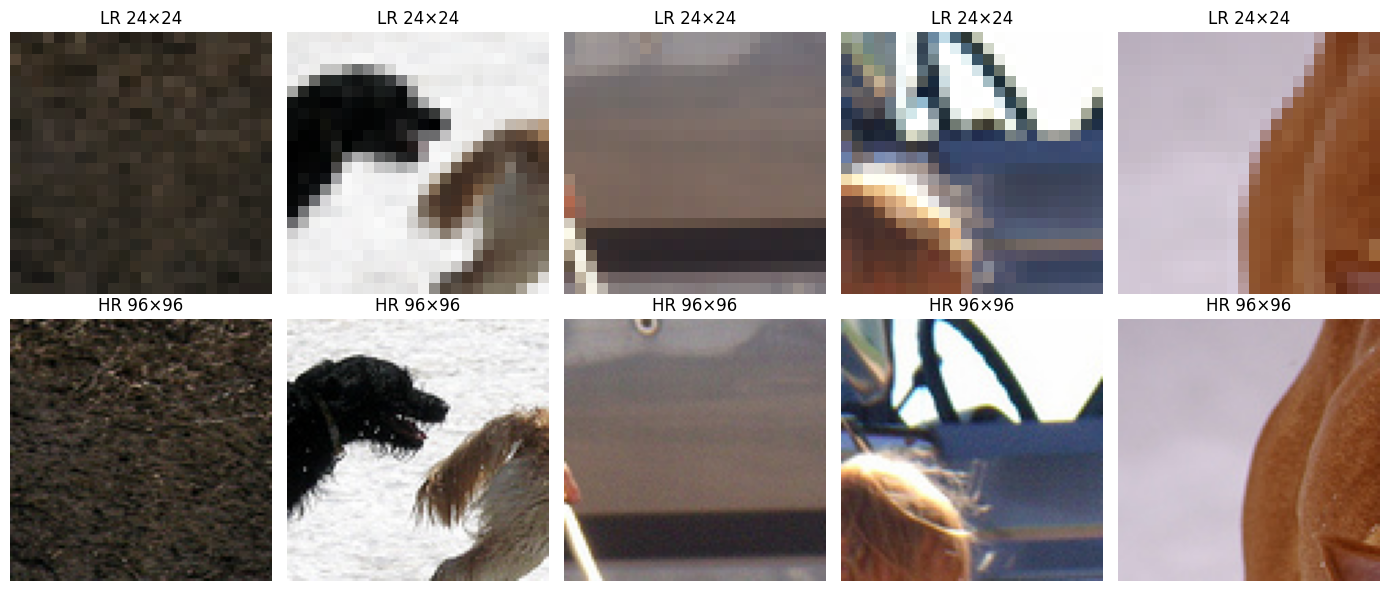

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for i in range(5):
    axes[0, i].imshow(lr_patches[i], interpolation="nearest"); axes[0, i].set_title("LR 24×24")
    axes[1, i].imshow(hr_patches[i]); axes[1, i].set_title("HR 96×96")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout(); plt.show()

Входы генератора нормируются в $[0, 1]$, выходы (и целевые HR) — в $[-1, 1]$, как в статье.
Аугментация — случайные отражения и повороты на 90°.

In [4]:
def augment(lr, hr):
    lr, hr = tf.cast(lr, tf.float32) / 255.0, tf.cast(hr, tf.float32) / 127.5 - 1.0
    if tf.random.uniform(()) > 0.5:
        lr, hr = tf.image.flip_left_right(lr), tf.image.flip_left_right(hr)
    k = tf.random.uniform((), 0, 4, dtype=tf.int32)
    return tf.image.rot90(lr, k), tf.image.rot90(hr, k)


train_ds = (tf.data.Dataset.from_tensor_slices((lr_patches, hr_patches))
            .shuffle(len(hr_patches)).map(augment).batch(BATCH_SIZE, drop_remainder=True).prefetch(2))

## 2. Генератор SRResNet

In [5]:
def residual_block(x, filters=64):
    y = tf.keras.layers.Conv2D(filters, 3, padding="same")(x)
    y = tf.keras.layers.BatchNormalization(momentum=0.8)(y)
    y = tf.keras.layers.PReLU(shared_axes=[1, 2])(y)
    y = tf.keras.layers.Conv2D(filters, 3, padding="same")(y)
    y = tf.keras.layers.BatchNormalization(momentum=0.8)(y)
    return tf.keras.layers.Add()([x, y])


def upsample(x, filters=256):
    x = tf.keras.layers.Conv2D(filters, 3, padding="same")(x)
    x = tf.keras.layers.Lambda(lambda t: tf.nn.depth_to_space(t, 2))(x)  # PixelShuffle ×2
    return tf.keras.layers.PReLU(shared_axes=[1, 2])(x)


def build_generator(n_blocks=8):
    inp = tf.keras.Input(shape=(None, None, 3))
    x = tf.keras.layers.Conv2D(64, 9, padding="same")(inp)
    x = skip = tf.keras.layers.PReLU(shared_axes=[1, 2])(x)
    for _ in range(n_blocks):
        x = residual_block(x)
    x = tf.keras.layers.Conv2D(64, 3, padding="same")(x)
    x = tf.keras.layers.BatchNormalization(momentum=0.8)(x)
    x = tf.keras.layers.Add()([skip, x])
    x = upsample(upsample(x))
    out = tf.keras.layers.Conv2D(3, 9, padding="same", activation="tanh")(x)
    return tf.keras.Model(inp, out, name="srresnet")


generator = build_generator()
print(f"Параметров генератора: {generator.count_params():,}")

Параметров генератора: 959,427


## 3. Этап 1: предобучение SRResNet по MSE

Предобученный по MSE генератор служит инициализацией для SRGAN и отдельной моделью для сравнения
(SRResNet даёт высокий PSNR, но более «размытые» текстуры).

In [6]:
g_opt = tf.keras.optimizers.Adam(1e-4)


@tf.function
def pretrain_step(lr, hr):
    with tf.GradientTape() as tape:
        loss = tf.reduce_mean(tf.square(generator(lr, training=True) - hr))
    g_opt.apply_gradients(zip(tape.gradient(loss, generator.trainable_variables), generator.trainable_variables))
    return loss


pretrain_hist = []
for epoch in range(PRETRAIN_EPOCHS):
    start = time.time()
    loss = np.mean([float(pretrain_step(lr, hr)) for lr, hr in train_ds])
    pretrain_hist.append(loss)
    print(f"Эпоха {epoch + 1}/{PRETRAIN_EPOCHS}: MSE={loss:.5f}  ({time.time() - start:.0f} с)")

os.makedirs(CKPT_DIR, exist_ok=True)
generator.save_weights(os.path.join(CKPT_DIR, "srresnet.weights.h5"))
srresnet = build_generator()
srresnet.set_weights(generator.get_weights())

Эпоха 1/8: MSE=0.08538  (149 с)


Эпоха 2/8: MSE=0.04900  (137 с)


Эпоха 3/8: MSE=0.04115  (137 с)


Эпоха 4/8: MSE=0.03679  (129 с)


Эпоха 5/8: MSE=0.03405  (130 с)


Эпоха 6/8: MSE=0.03269  (132 с)


Эпоха 7/8: MSE=0.03116  (130 с)


Эпоха 8/8: MSE=0.03059  (130 с)


## 4. Этап 2: SRGAN

**Дискриминатор** — последовательность свёрток 3×3 с ростом числа фильтров (64→512) и шагом 2 через слой,
затем два полносвязных слоя. **Perceptual loss** — MSE между признаками слоя `block5_conv4`
сети VGG19 (предобученной на ImageNet) для SR и HR изображений, делённая на 12.75² как в статье.

Первый прогон с чисто VGG-потерей (как в статье) за 3 эпохи давал заметный сдвиг цвета и «шахматные»
артефакты: признаки глубокого слоя VGG почти нечувствительны к цвету, а для их устранения нужно
гораздо больше итераций, чем доступно на CPU. Поэтому, как во многих реализациях SRGAN, к perceptual
loss добавлена поточечная MSE, которая удерживает цвета и общую яркость:

$$\mathcal{L}_G = \mathrm{MSE}(SR, HR) + 0.1 \cdot \mathcal{L}_{VGG} + 10^{-3} \cdot \mathcal{L}_{adv}$$

Вес 0.1 подобран так, чтобы вклады MSE и VGG были одного порядка (для предобученного SRResNet
MSE ≈ 0.025, $\mathcal{L}_{VGG}$ ≈ 0.31).

In [7]:
def build_discriminator():
    inp = tf.keras.Input(shape=(HR, HR, 3))
    x = tf.keras.layers.Conv2D(64, 3, padding="same")(inp)
    x = tf.keras.layers.LeakyReLU(0.2)(x)
    for filters, strides in [(64, 2), (128, 1), (128, 2), (256, 1), (256, 2), (512, 1), (512, 2)]:
        x = tf.keras.layers.Conv2D(filters, 3, strides=strides, padding="same")(x)
        x = tf.keras.layers.BatchNormalization(momentum=0.8)(x)
        x = tf.keras.layers.LeakyReLU(0.2)(x)
    x = tf.keras.layers.Flatten()(x)
    x = tf.keras.layers.Dense(1024)(x)
    x = tf.keras.layers.LeakyReLU(0.2)(x)
    return tf.keras.Model(inp, tf.keras.layers.Dense(1)(x), name="discriminator")


discriminator = build_discriminator()

vgg = tf.keras.applications.VGG19(include_top=False, weights="imagenet", input_shape=(HR, HR, 3))
vgg_features = tf.keras.Model(vgg.input, vgg.get_layer("block5_conv4").output)
vgg_features.trainable = False


def vgg_embed(x):
    """x в [-1, 1] -> признаки VGG19 (со стандартной предобработкой Caffe)."""
    return vgg_features(tf.keras.applications.vgg19.preprocess_input((x + 1) * 127.5)) / 12.75


bce = tf.keras.losses.BinaryCrossentropy(from_logits=True)
g_opt = tf.keras.optimizers.Adam(1e-4)
d_opt = tf.keras.optimizers.Adam(1e-4)


@tf.function
def gan_step(lr, hr):
    with tf.GradientTape() as g_tape, tf.GradientTape() as d_tape:
        sr = generator(lr, training=True)
        d_real = discriminator(hr, training=True)
        d_fake = discriminator(sr, training=True)

        pixel = tf.reduce_mean(tf.square(sr - hr))
        content = tf.reduce_mean(tf.square(vgg_embed(sr) - vgg_embed(hr)))
        adversarial = bce(tf.ones_like(d_fake), d_fake)
        g_loss = pixel + 0.1 * content + 1e-3 * adversarial
        d_loss = bce(tf.ones_like(d_real), d_real) + bce(tf.zeros_like(d_fake), d_fake)

    g_opt.apply_gradients(zip(g_tape.gradient(g_loss, generator.trainable_variables), generator.trainable_variables))
    d_opt.apply_gradients(zip(d_tape.gradient(d_loss, discriminator.trainable_variables), discriminator.trainable_variables))
    return pixel, content, adversarial, d_loss


gan_hist = []
for epoch in range(GAN_EPOCHS):
    start = time.time()
    losses = np.array([[float(v) for v in gan_step(lr, hr)] for lr, hr in train_ds]).mean(axis=0)
    gan_hist.append(losses)
    print(f"Эпоха {epoch + 1}/{GAN_EPOCHS}: MSE={losses[0]:.4f}  VGG={losses[1]:.4f}  G_adv={losses[2]:.3f}  D={losses[3]:.3f}  ({time.time() - start:.0f} с)")

generator.save_weights(os.path.join(CKPT_DIR, "srgan.weights.h5"))

Эпоха 1/3: MSE=0.0329  VGG=0.2966  G_adv=5.242  D=0.629  (678 с)


Эпоха 2/3: MSE=0.0356  VGG=0.3052  G_adv=8.928  D=0.242  (643 с)


Эпоха 3/3: MSE=0.0369  VGG=0.3149  G_adv=8.057  D=0.486  (652 с)


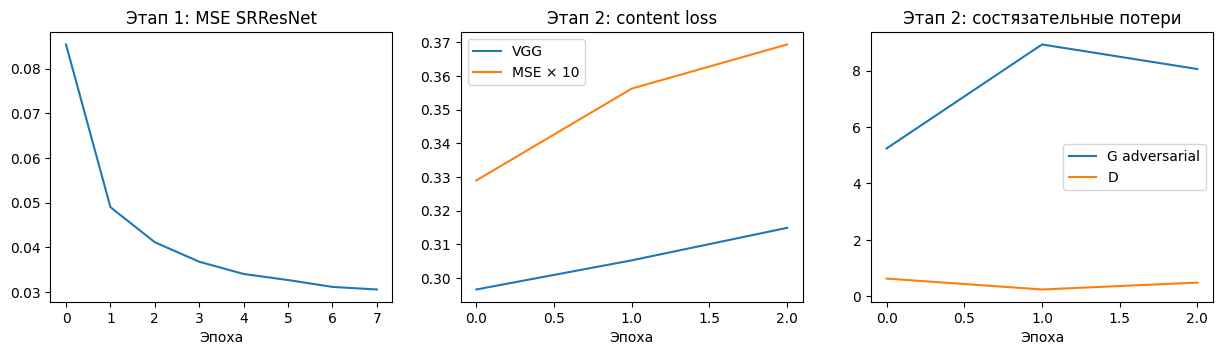

In [8]:
gan_hist = np.array(gan_hist)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(pretrain_hist); axes[0].set_title("Этап 1: MSE SRResNet")
axes[1].plot(gan_hist[:, 1], label="VGG"); axes[1].plot(gan_hist[:, 0] * 10, label="MSE × 10")
axes[1].set_title("Этап 2: content loss"); axes[1].legend()
axes[2].plot(gan_hist[:, 2], label="G adversarial"); axes[2].plot(gan_hist[:, 3], label="D")
axes[2].set_title("Этап 2: состязательные потери"); axes[2].legend()
for ax in axes:
    ax.set_xlabel("Эпоха")
plt.show()

## 5. Тестирование

Из 100 тестовых фотографий вырезается центральный фрагмент 256×256 (HR), уменьшается до 64×64 (LR)
и восстанавливается тремя способами: бикубической интерполяцией, SRResNet и SRGAN.
Метрики — PSNR и SSIM по яркостному каналу Y (как принято в задачах super-resolution).

In [9]:
def center_crop(img, size=256):
    h, w = img.shape[:2]
    y, x = (h - size) // 2, (w - size) // 2
    return img[y:y + size, x:x + size]


test_imgs = (np.asarray(Image.open(p).convert("RGB")) for p in read_split("test"))
test_hr = np.stack([center_crop(x) for x in test_imgs if min(x.shape[:2]) >= 256][:100])
test_lr = np.stack([downscale(x) for x in test_hr])


def super_resolve(model, lr_batch):
    out = model.predict(lr_batch.astype("float32") / 255.0, batch_size=10, verbose=0)
    return np.clip((out + 1) * 127.5, 0, 255).round().astype(np.uint8)


def bicubic(lr_batch):
    return np.stack([np.asarray(Image.fromarray(x).resize((x.shape[1] * SCALE, x.shape[0] * SCALE), Image.BICUBIC)) for x in lr_batch])


def y_channel(x):
    return tf.image.rgb_to_yuv(tf.cast(x, tf.float32) / 255.0)[..., :1]


def evaluate(sr, hr):
    sr_y, hr_y = y_channel(sr)[:, 4:-4, 4:-4], y_channel(hr)[:, 4:-4, 4:-4]  # без краёв, как в статье
    return {"PSNR, дБ": float(tf.reduce_mean(tf.image.psnr(sr_y, hr_y, 1.0))),
            "SSIM": float(tf.reduce_mean(tf.image.ssim(sr_y, hr_y, 1.0)))}


results = {"Бикубическая": bicubic(test_lr), "SRResNet (MSE)": super_resolve(srresnet, test_lr),
           "SRGAN": super_resolve(generator, test_lr)}
pd.DataFrame({name: evaluate(sr, test_hr) for name, sr in results.items()}).T.round(4)

,"PSNR, дБ",SSIM
Бикубическая,23.0484,0.6238
SRResNet (MSE),22.9920,0.6246
SRGAN,22.1216,0.5633


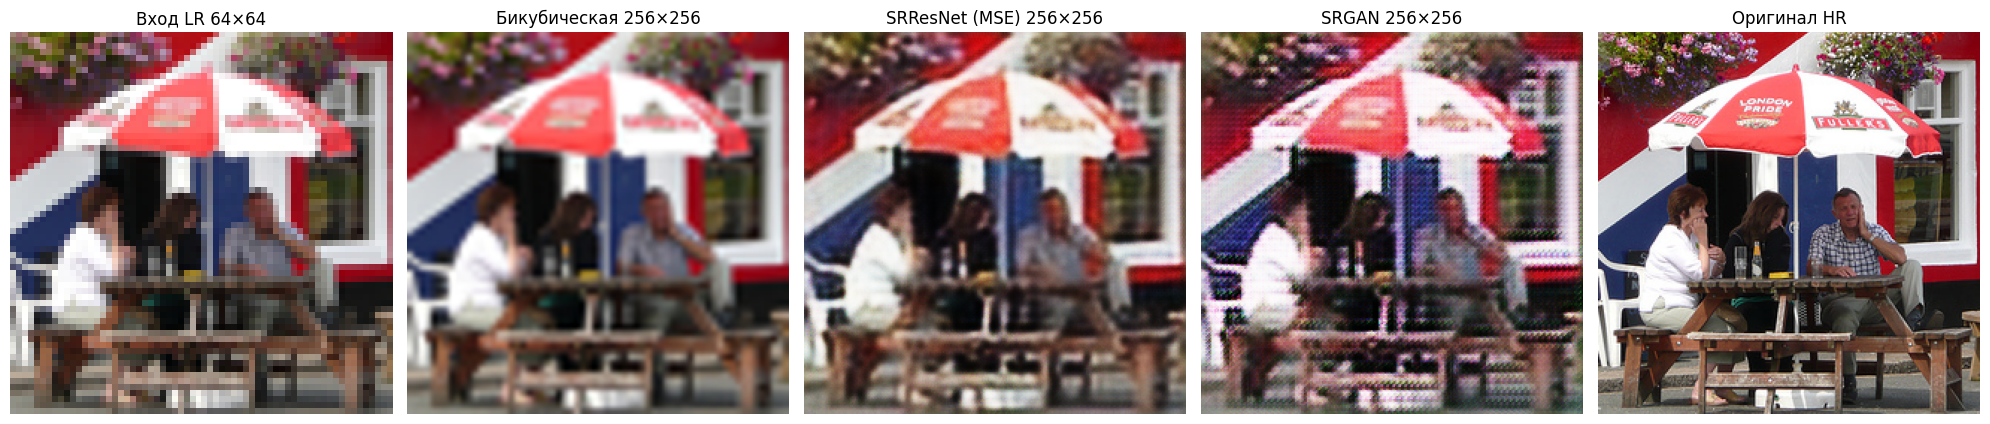

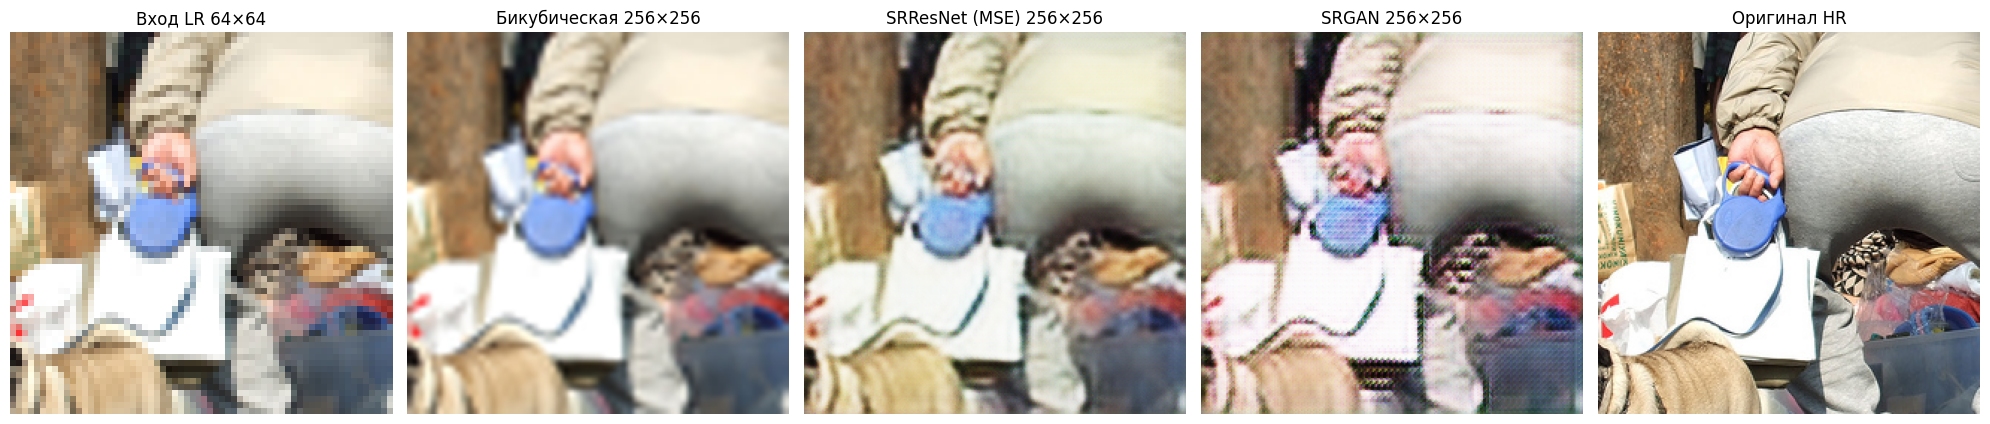

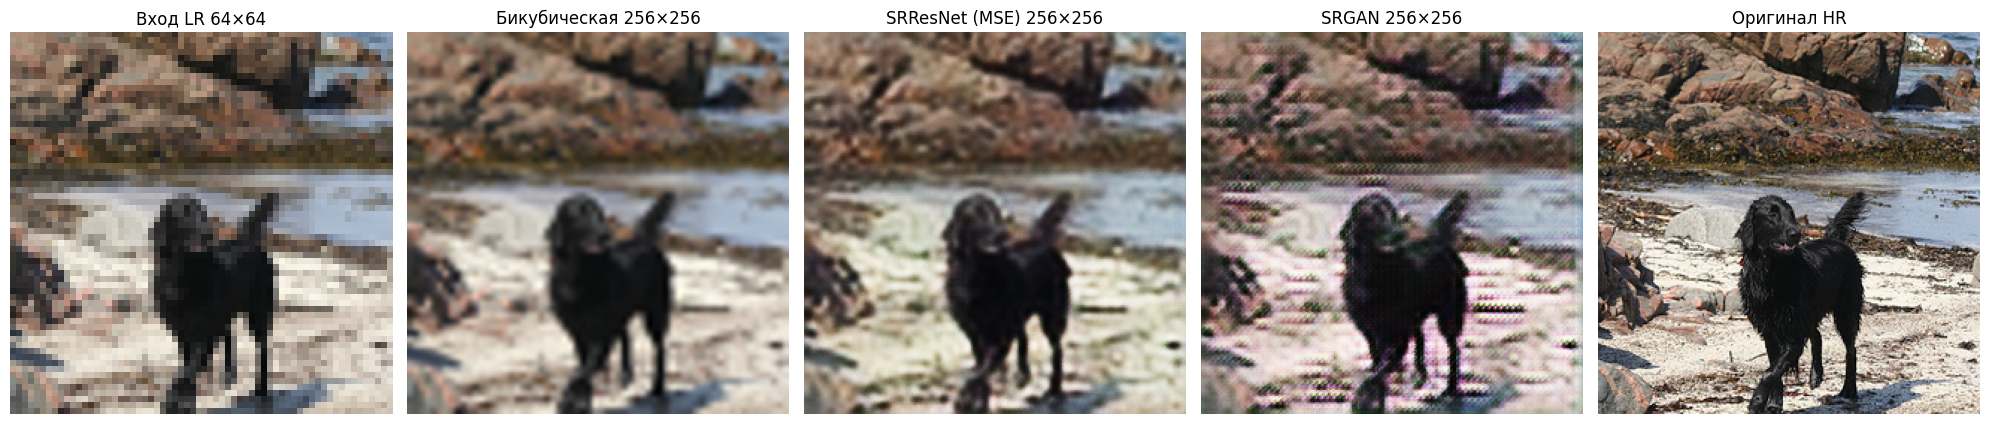

In [10]:
for i in [3, 27, 58]:
    fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))
    axes[0].imshow(test_lr[i], interpolation="nearest"); axes[0].set_title("Вход LR 64×64")
    for ax, (name, sr) in zip(axes[1:4], results.items()):
        ax.imshow(sr[i]); ax.set_title(f"{name} 256×256")
    axes[4].imshow(test_hr[i]); axes[4].set_title("Оригинал HR")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout(); plt.show()

### Фрагменты крупным планом

На увеличенных участках видно различие подходов: бикубическая интерполяция и SRResNet дают
сглаженные края, а SRGAN пытается добавить высокочастотные детали (см. выводы).

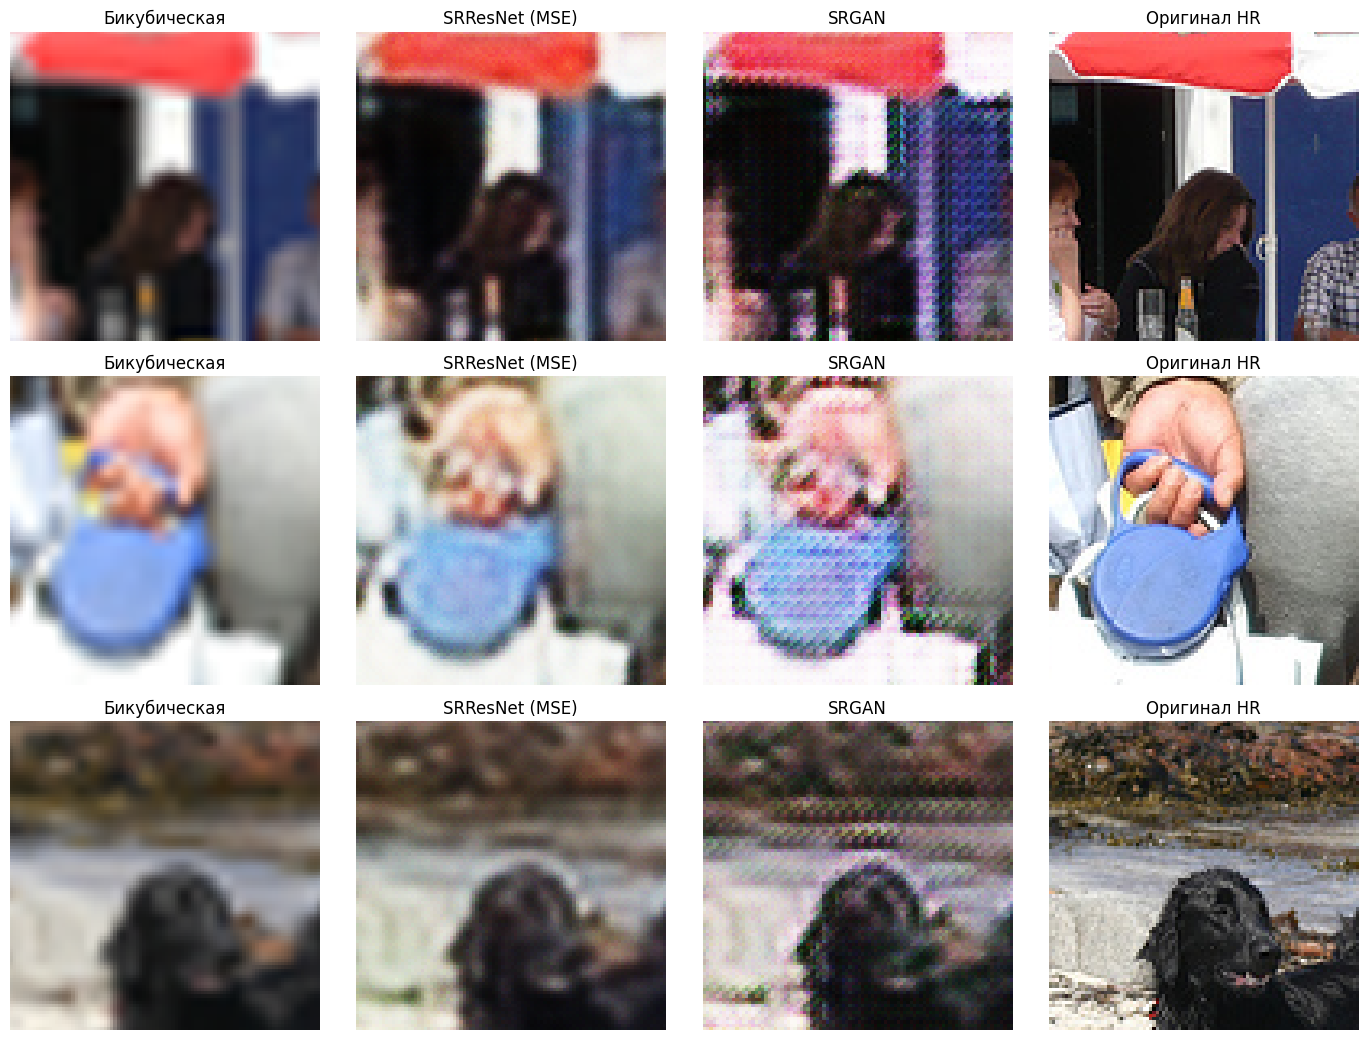

In [11]:
fig, axes = plt.subplots(3, 4, figsize=(14, 10.5))
for r, i in enumerate([3, 27, 58]):
    crop = (slice(64, 160), slice(64, 160))
    for c, (name, img) in enumerate([*results.items(), ("Оригинал HR", test_hr)]):
        axes[r, c].imshow(img[i][crop], interpolation="nearest"); axes[r, c].set_title(name); axes[r, c].axis("off")
plt.tight_layout(); plt.show()

## 6. Применение к произвольному изображению

Генератор полностью свёрточный, поэтому принимает изображение любого размера. Функция
`upscale_image` читает файл `.png`/`.bmp`/`.jpg` и сохраняет результат с разрешением ×4.

In [12]:
def upscale_image(path, out_path, model=generator):
    lr = np.asarray(Image.open(path).convert("RGB"))
    Image.fromarray(super_resolve(model, lr[None])[0]).save(out_path)
    return out_path


Image.fromarray(test_lr[10]).save("example_lr.png")
upscale_image("example_lr.png", "example_sr.png")
print("Вход:", Image.open("example_lr.png").size, "→ выход:", Image.open("example_sr.png").size)

Вход: (64, 64) → выход: (256, 256)


## Выводы

* Реализован полный конвейер SRGAN: формирование пар LR/HR из открытого датасета, генератор SRResNet
  с субпиксельными свёртками, дискриминатор, двухэтапное обучение (MSE → perceptual + adversarial)
  и функция `upscale_image` для изображений произвольного размера.
* На тесте (100 фрагментов 256×256 из Flickr8k, ×4) SRResNet после 8 эпох (≈2000 итераций) по
  PSNR/SSIM находится на уровне бикубической интерполяции (≈23.0 дБ / 0.62), но визуально даёт более
  чёткие контуры. В статье SRResNet обучался 10⁶ итераций на 350 тыс. изображений ImageNet и
  опережал бикубическую интерполяцию на ≈2–3 дБ — основная причина разрыва в объёме обучения.
* SRGAN, как и ожидалось по статье, проигрывает по PSNR/SSIM (22.1 дБ / 0.56): состязательная и
  perceptual-потери оптимизируют не попиксельную точность, а «естественность» текстур. Первый прогон
  с чистой VGG-потерей сдвигал цвета; добавление поточечной MSE это устранило.
* За 3 эпохи GAN (≈750 итераций против 10⁵ в статье) генератор ещё не научился правдоподобным
  текстурам: дискриминатор доминирует (G_adv растёт до ≈8), и генератор отвечает регулярной
  высокочастотной «сеткой» — типичными артефактами ранней стадии обучения SRGAN и субпиксельных свёрток.
  Для качественного результата нужны GPU и обучение на порядки дольше; также помогают инициализация
  ICNR для PixelShuffle, меньшая скорость обучения дискриминатора и вес adversarial-потери.